<a href="https://colab.research.google.com/github/Praneeth-97-Pv/Image-Processing-and-Visualization-with-FluidDyn-s-fluidimage/blob/main/fluidimage_piv_assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install "rich>=12.4.4,<14"

  Attempting uninstall: rich
    Found existing installation: rich 15.0.0
    Uninstalling rich-15.0.0:
      Successfully uninstalled rich-15.0.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
textual 8.2.8 requires rich>=14.2.0, but you have rich 13.9.4 which is incompatible.


In [ ]:
import fluidimage
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("FluidImage installed successfully!")
print("FluidImage version:", fluidimage.__version__)

FluidImage installed successfully!
FluidImage version: 0.5.5


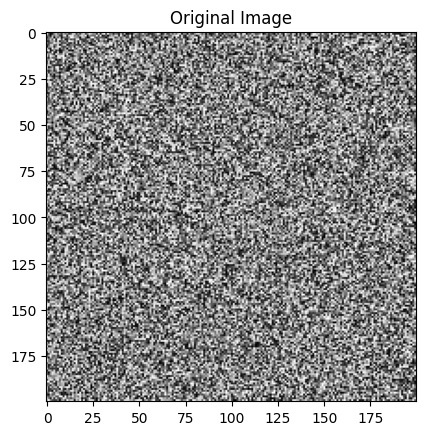

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Generate sample grayscale image
img = np.random.randint(0, 256, (200, 200), dtype=np.uint8)

# Display image
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.show()

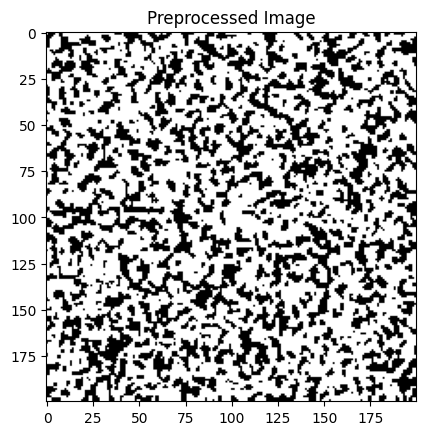

In [ ]:
import cv2

img_blur = cv2.GaussianBlur(img, (5, 5), 0)

_, img_thresh = cv2.threshold(
    img_blur, 120, 255, cv2.THRESH_BINARY
)

plt.imshow(img_thresh, cmap="gray")
plt.title("Preprocessed Image")
plt.show()

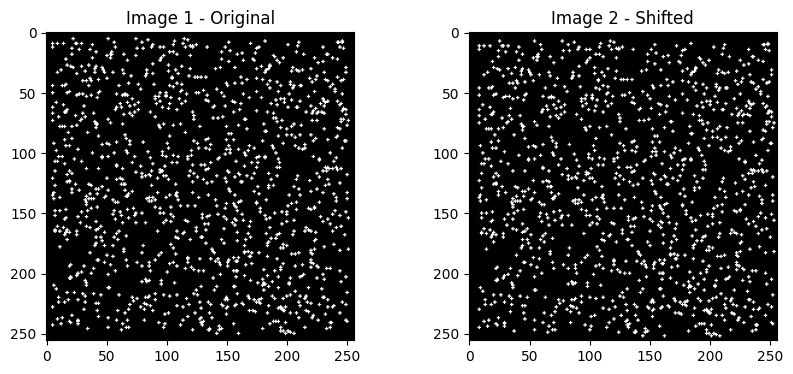

In [ ]:

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Create folder to store images
os.makedirs("piv_images", exist_ok=True)

# Create first particle image
np.random.seed(42)
img1 = np.zeros((256, 256), dtype=np.uint8)

for i in range(1200):
    x = np.random.randint(5, 251)
    y = np.random.randint(5, 251)
    cv2.circle(img1, (x, y), 1, 255, -1)

# Create second image with particle movement
M = np.float32([
    [1, 0, 3],
    [0, 1, 2]
])

img2 = cv2.warpAffine(img1, M, (256, 256))

# Save both images
cv2.imwrite("piv_images/frame_01.png", img1)
cv2.imwrite("piv_images/frame_02.png", img2)

# Display images
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img1, cmap="gray")
plt.title("Image 1 - Original")

plt.subplot(1, 2, 2)
plt.imshow(img2, cmap="gray")
plt.title("Image 2 - Shifted")

plt.show()


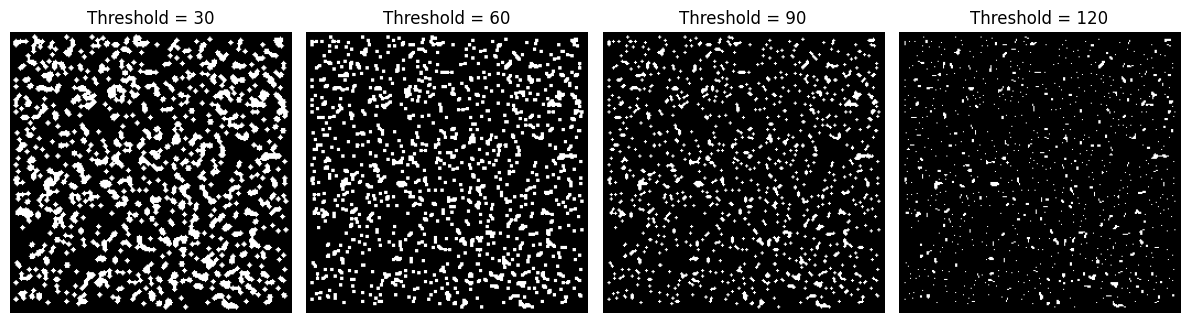

In [ ]:

img_blur = cv2.GaussianBlur(img1, (5, 5), 0)

threshold_values = [30, 60, 90, 120]

plt.figure(figsize=(12, 4))

for i, value in enumerate(threshold_values):
    _, processed = cv2.threshold(
        img_blur, value, 255, cv2.THRESH_BINARY
    )

    plt.subplot(1, 4, i + 1)
    plt.imshow(processed, cmap="gray")
    plt.title(f"Threshold = {value}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

from fluidimage.piv import Work

params = Work.create_default_params()

# Input images
params.series.path = "piv_images/*.png"

# PIV settings
params.piv0.method_correl = "np.fft"
params.piv0.method_subpix = "centroid"
params.piv0.shape_crop_im0 = 32
params.piv0.displacement_max = 8

# Number of passes
params.multipass.number = 1

print("PIV parameters configured!")


PIV parameters configured!


In [ ]:

work = Work(params=params)

# Process one pair of images
piv = work.process_1_serie()

print("PIV analysis completed!")


Process from arrays ('frame_01.png', 'frame_02.png')
TPS interpolation (frame_01.png-frame_02.png, smoothing_coef=5.0, threshold=1.5).
TPS summary: no erratic vector found.
  Statistics on the 2 TPS subdomains:
    nb_fixed_vectors  : min=0; max=0; mean=0.000
    max(Udiff)        : min=0.013; max=0.017; mean=0.015
    nb_iterations     : min=1; max=1; mean=1.000
Calcul done in 0.08 s
PIV analysis completed!


press alt+h for help and legend


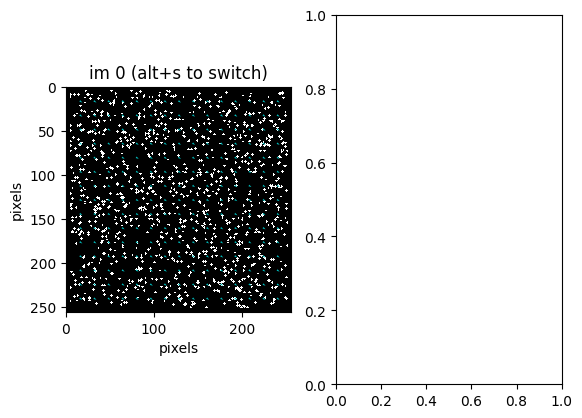

In [ ]:

piv.display(
    show_interp=False,
    scale=1,
    show_error=True
)

plt.show()


In [ ]:
params.piv0.method_subpix = "2d_gaussian2"

print("Subpixel method:", params.piv0.method_subpix)

Subpixel method: 2d_gaussian2


In [ ]:

# Save the computed PIV data
piv.save()

print("PIV results saved!")

PIV results saved!


In [ ]:
print("piv exists:", "piv" in globals())
print("piv_gaussian exists:", "piv_gaussian" in globals())

piv exists: True
piv_gaussian exists: False


In [ ]:
from fluidimage.piv import Work

# Select Gaussian subpixel method
params.piv0.method_subpix = "2d_gaussian2"

# Initialize PIV
work = Work(params=params)

# Execute PIV calculation
piv_gaussian = work.process_1_serie()

print("Gaussian PIV calculation completed!")

Process from arrays ('frame_01.png', 'frame_02.png')
TPS interpolation (frame_01.png-frame_02.png, smoothing_coef=5.0, threshold=1.5).
TPS summary: no erratic vector found.
  Statistics on the 2 TPS subdomains:
    nb_fixed_vectors  : min=0; max=0; mean=0.000
    max(Udiff)        : min=0.355; max=0.374; mean=0.364
    nb_iterations     : min=1; max=1; mean=1.000
Calcul done in 0.07 s
Gaussian PIV calculation completed!


In [ ]:
M = np.float32([
    [1, 0, 3],
    [0, 1, 2]
])

In [ ]:
M = np.float32([
    [1, 0, 3],
    [0, 1, 2]
])

img2 = cv2.warpAffine(img1, M, (256, 256))

In [ ]:
import numpy as np

dx = M[0, 2]
dy = M[1, 2]

magnitude = np.sqrt(dx**2 + dy**2)

print("Horizontal displacement:", dx, "pixels")
print("Vertical displacement:", dy, "pixels")
print("Expected magnitude:", round(magnitude, 2), "pixels")

Horizontal displacement: 3.0 pixels
Vertical displacement: 2.0 pixels
Expected magnitude: 3.61 pixels


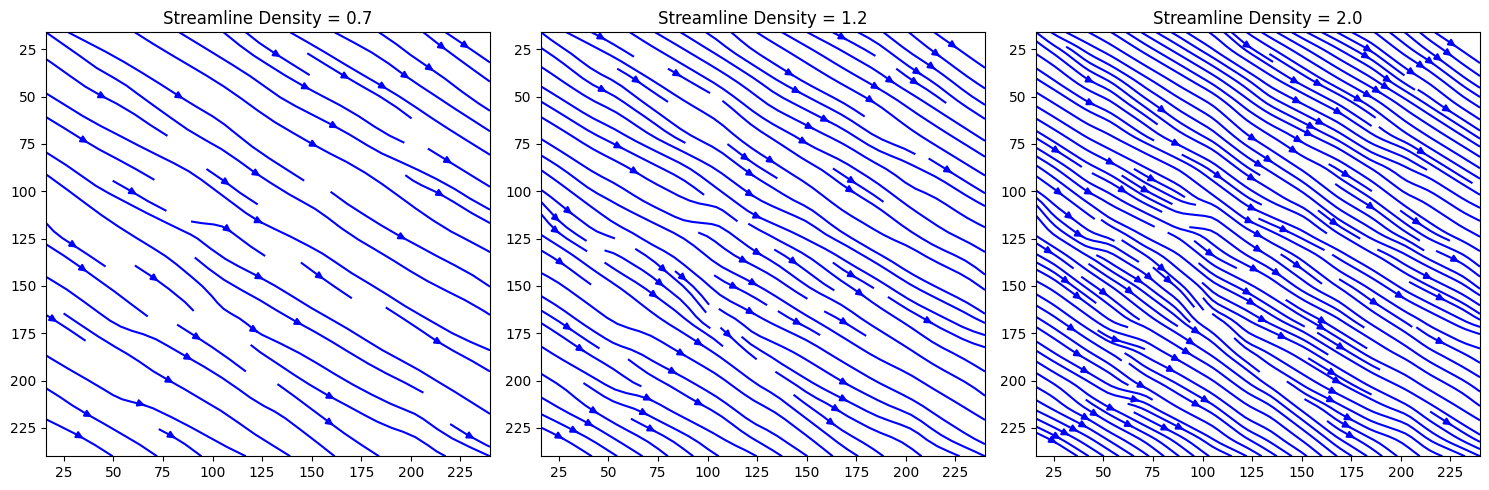

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import griddata

# Access the actual PIV result
result = piv_gaussian.piv0

x = np.asarray(result.xs).ravel()
y = np.asarray(result.ys).ravel()
u = np.asarray(result.deltaxs).ravel()
v = np.asarray(result.deltays).ravel()

valid = (
    np.isfinite(x) &
    np.isfinite(y) &
    np.isfinite(u) &
    np.isfinite(v)
)

points = np.column_stack((x[valid], y[valid]))

grid_x = np.linspace(x[valid].min(), x[valid].max(), 40)
grid_y = np.linspace(y[valid].min(), y[valid].max(), 40)
X, Y = np.meshgrid(grid_x, grid_y)

U = griddata(points, u[valid], (X, Y), method="nearest")
V = griddata(points, v[valid], (X, Y), method="nearest")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, density in zip(axes, [0.7, 1.2, 2.0]):
    ax.streamplot(
        grid_x, grid_y, U, V,
        density=density,
        color="blue"
    )
    ax.set_title(f"Streamline Density = {density}")
    ax.invert_yaxis()

plt.tight_layout()
plt.savefig("streamline_comparison.png", dpi=200)
plt.show()

In [ ]:
def summarize_piv(result):
    p = result.piv0

    u = np.asarray(p.deltaxs).ravel()
    v = np.asarray(p.deltays).ravel()

    valid = np.isfinite(u) & np.isfinite(v)

    return {
        "valid_vectors": int(valid.sum()),
        "median_dx": float(np.median(u[valid])),
        "median_dy": float(np.median(v[valid]))
    }

centroid_stats = summarize_piv(piv)
gaussian_stats = summarize_piv(piv_gaussian)

print("Centroid:", centroid_stats)
print("Gaussian:", gaussian_stats)

Centroid: {'valid_vectors': 225, 'median_dx': 2.982133150100708, 'median_dy': 1.9823824167251587}
Gaussian: {'valid_vectors': 225, 'median_dx': 2.781205654144287, 'median_dy': 1.7764663696289062}
